# 07 · A learned decoder for the repetition code

**QGAI open notebooks · Track: Quantum-AI Convergence (AI for quantum)**

Quantum error correction spreads one logical bit over several physical qubits and measures **syndromes**, parity checks that reveal *that* an
error happened without revealing the data. A **decoder** must guess from the syndrome which error occurred. Decoders must be accurate and,
on real hardware, fast; machine learning is one of the main approaches being explored.

We use the simplest code, the **distance-5 bit-flip repetition code** (5 data qubits, 4 parity checks), and compare three decoders under two noise models:

| Decoder | How it decides |
|---|---|
| Minimum weight (textbook) | assume the error that flips the fewest qubits |
| Learned (small neural network) | trained on simulated (syndrome, error) examples |
| Maximum likelihood (exact) | uses the true noise model; the best any decoder can do |

| Noise model | Description |
|---|---|
| Independent | each qubit flips with probability $p$ |
| Correlated | as above, plus neighbouring **pairs** flip together (crosstalk), a common effect in real devices |

In [1]:
import itertools
import numpy as np
import pennylane as qml
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

SEED = 4
rng = np.random.default_rng(SEED)
D = 5                                    # data qubits
CHECKS = [(i, i + 1) for i in range(D - 1)]

def syndrome(e):
    """Parity of each neighbouring pair: 1 where exactly one of the two qubits flipped."""
    e = np.atleast_2d(e)
    return np.stack([e[:, i] ^ e[:, j] for i, j in CHECKS], 1)

## Step 1: check the syndrome circuit on a quantum simulator
9 qubits: 5 data qubits and 4 ancillas. Each ancilla collects the parity of two neighbouring data qubits through two CNOTs and is then measured.
We inject a few bit-flip patterns and confirm the circuit reports the same syndromes as the classical formula used in the rest of the notebook.

In [2]:
dev = qml.device("default.qubit", wires=D + len(CHECKS))

@qml.set_shots(1)
@qml.qnode(dev)
def measure_syndrome(error):
    for q in range(D):
        if error[q]: qml.PauliX(q)                     # inject bit flips on the data qubits
    for a, (i, j) in enumerate(CHECKS):
        qml.CNOT(wires=[i, D + a]); qml.CNOT(wires=[j, D + a])
    return qml.sample(wires=range(D, D + len(CHECKS)))

for err in [(0, 0, 0, 0, 0), (1, 0, 0, 0, 0), (0, 0, 1, 0, 0), (0, 1, 1, 0, 0), (1, 1, 1, 1, 1)]:
    quantum = np.asarray(measure_syndrome(np.array(err))).ravel().astype(int)
    classical = syndrome(np.array(err))[0]
    assert np.array_equal(quantum, classical)
    print(f"error {err} -> syndrome {tuple(int(b) for b in quantum)}  (matches formula)")
print("Note: flipping all five qubits gives syndrome (0,0,0,0) — undetectable, it flips the logical bit.")

error (0, 0, 0, 0, 0) -> syndrome (0, 0, 0, 0)  (matches formula)
error (1, 0, 0, 0, 0) -> syndrome (1, 0, 0, 0)  (matches formula)
error (0, 0, 1, 0, 0) -> syndrome (0, 1, 1, 0)  (matches formula)
error (0, 1, 1, 0, 0) -> syndrome (1, 0, 1, 0)  (matches formula)
error (1, 1, 1, 1, 1) -> syndrome (0, 0, 0, 0)  (matches formula)
Note: flipping all five qubits gives syndrome (0,0,0,0) — undetectable, it flips the logical bit.


## Step 2: noise models and the exact (maximum-likelihood) answer
For every syndrome exactly two error patterns are consistent with it: some pattern $e$ and its complement $\bar e$. Choosing the wrong one
flips the logical bit. Maximum likelihood picks whichever of the two is more probable under the true noise.

In [3]:
ALL = np.array(list(itertools.product([0, 1], repeat=D)))

def sample_errors(n, p, pair_p):
    e = (rng.random((n, D)) < p).astype(int)
    if pair_p > 0:
        for i, j in CHECKS:                            # neighbouring pairs flip together with prob pair_p
            hit = rng.random(n) < pair_p
            e[hit, i] ^= 1; e[hit, j] ^= 1
    return e

def exact_probs(p, pair_p):
    """Exact probability of each 5-bit error pattern under the noise model (enumerate all pair events)."""
    prob = np.zeros(len(ALL))
    for pairs in itertools.product([0, 1], repeat=len(CHECKS)):
        w_pairs = np.prod([pair_p if b else 1 - pair_p for b in pairs])
        base = np.zeros(D, int)
        for b, (i, j) in zip(pairs, CHECKS):
            if b: base[i] ^= 1; base[j] ^= 1
        for k, e in enumerate(ALL):
            indep = e ^ base                            # independent flips needed on top of the pair flips
            prob[k] += w_pairs * np.prod(np.where(indep == 1, p, 1 - p))
    return prob

def canonical(e):
    """Represent each error by the member of {e, complement} with qubit 0 unflipped; label = whether e is the complement."""
    e = np.atleast_2d(e); flip = e[:, 0] == 1
    return np.where(flip[:, None], 1 - e, e), flip.astype(int)

def logical_error_rate(decide, errors):
    """decide(syndromes) -> 1 if the decoder applies the complement of the canonical correction."""
    syn = syndrome(errors); _, label = canonical(errors)
    return float(np.mean(decide(syn) != label))

def min_weight_decoder(syn):
    canon = np.array([[0] + list(np.cumsum(s) % 2) for s in syn])   # rebuild the pattern with qubit 0 unflipped
    return (canon.sum(1) > D - canon.sum(1)).astype(int)            # pick the complement if it flips fewer qubits

def ml_decoder_for(p, pair_p):
    prob = exact_probs(p, pair_p)
    table = {}
    for k, e in enumerate(ALL):
        s = tuple(syndrome(e)[0]); _, lab = canonical(e)
        table.setdefault(s, np.zeros(2))[lab[0]] += prob[k]
    return lambda syn: np.array([int(np.argmax(table[tuple(s)])) for s in syn])

## Step 3: train a small neural decoder for each noise setting and compare
The network sees only simulated syndromes and the true error class: 20,000 examples per setting. It knows nothing about the noise model.
Each decoder is then tested on 200,000 fresh samples.

noise                        p  min weight   learned  max likelihood
Independent               0.02      0.0001    0.0008          0.0001
Independent               0.05      0.0010    0.0010          0.0010
Independent               0.08      0.0046    0.0046          0.0046
Independent               0.11      0.0113    0.0113          0.0113
Independent               0.14      0.0221    0.0221          0.0221
Correlated (pair flips)   0.02      0.0226    0.0202          0.0197
Correlated (pair flips)   0.05      0.0375    0.0350          0.0347
Correlated (pair flips)   0.08      0.0519    0.0500          0.0500
Correlated (pair flips)   0.11      0.0685    0.0685          0.0672
Correlated (pair flips)   0.14      0.0853    0.0863          0.0853


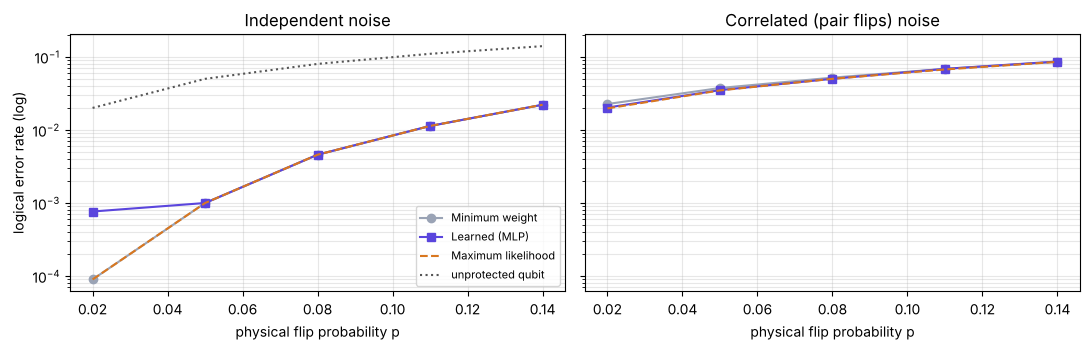

In [4]:
P_RANGE = [0.02, 0.05, 0.08, 0.11, 0.14]
SETTINGS = {"Independent": 0.0, "Correlated (pair flips)": 0.06}
table_rows, curves = [], {}
for name, pair_p in SETTINGS.items():
    curves[name] = {"Minimum weight": [], "Learned (MLP)": [], "Maximum likelihood": []}
    for p in P_RANGE:
        train = sample_errors(20_000, p, pair_p); test = sample_errors(200_000, p, pair_p)
        mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, random_state=SEED)
        mlp.fit(syndrome(train), canonical(train)[1])
        rates = {
            "Minimum weight": logical_error_rate(min_weight_decoder, test),
            "Learned (MLP)": logical_error_rate(lambda s: mlp.predict(s), test),
            "Maximum likelihood": logical_error_rate(ml_decoder_for(p, pair_p), test),
        }
        for k, v in rates.items(): curves[name][k].append(v)
        table_rows.append((name, p, rates))

print(f"{'noise':24s} {'p':>5s} {'min weight':>11s} {'learned':>9s} {'max likelihood':>15s}")
for name, p, r in table_rows:
    print(f"{name:24s} {p:>5.2f} {r['Minimum weight']:>11.4f} {r['Learned (MLP)']:>9.4f} {r['Maximum likelihood']:>15.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
style = {"Minimum weight": ("#9aa3b5", "o-"), "Learned (MLP)": ("#5a45dd", "s-"), "Maximum likelihood": ("#d9771f", "--")}
for ax, name in zip(axes, SETTINGS):
    for k, (c, ls) in style.items():
        ax.plot(P_RANGE, curves[name][k], ls, color=c, label=k)
    if name == "Independent":
        ax.plot(P_RANGE, P_RANGE, ":", color="#555", label="unprotected qubit")
    ax.set_title(f"{name} noise"); ax.set_xlabel("physical flip probability p"); ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("logical error rate (log)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Reading the results honestly

- **Independent noise:** the textbook minimum-weight decoder *is* the maximum-likelihood decoder here, so nothing can beat it. The learned decoder matches it at most error rates, but at the lowest one ($p = 0.02$) it is several times worse. Some syndromes are so rare that 20,000 training examples barely contain them. **Starving for rare events at low error rates is a known weakness of learned decoders**, and real hardware operates exactly in that regime.
- **Correlated noise:** minimum weight is no longer optimal, because it assumes errors are independent. The learned decoder, never told about the pair flips, closes most of the gap to the maximum-likelihood optimum at low error rates (see $p = 0.02$–$0.05$ above). At higher error rates all decoders converge and the learned one is occasionally slightly worse.
- **Correlated noise is damaging in itself:** logical error rates are far higher than with independent noise at the same $p$. A better decoder cannot fully compensate for a code that doesn't match the noise.

**Caveats:** with only 16 possible syndromes, a lookup table counted from the same training data would do as well as the neural network. Learned decoders earn their keep on large codes (surface and qLDPC codes) with noisy measurements over many rounds, where tables are impossible, and they must also meet microsecond latency budgets. This notebook shows the principle, not that regime.

**Try next:** add measurement errors and repeated syndrome rounds; train with importance sampling of rare syndromes; scale to a small surface code.